<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 09 · Quantum transport II: multi-terminal devices, quantum Hall and quantum spin Hall

Landauer-Büttiker: $I_i=\frac{e}{h}\sum_j G_{ij}V_j$ with $G_{ij}=-T_{ij}$ for $i\neq j$.
A magnetic field enters through Peierls phases $t_{ij}\to t_{ij}e^{i\int A\cdot dl}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline
from hopforge import transport as tr
from hopforge import kpm

## 1. A six-terminal Hall bar
The current leads (0, 1) carry the field in a Landau gauge that is invariant along x; the voltage probes (2–5) are field-free.

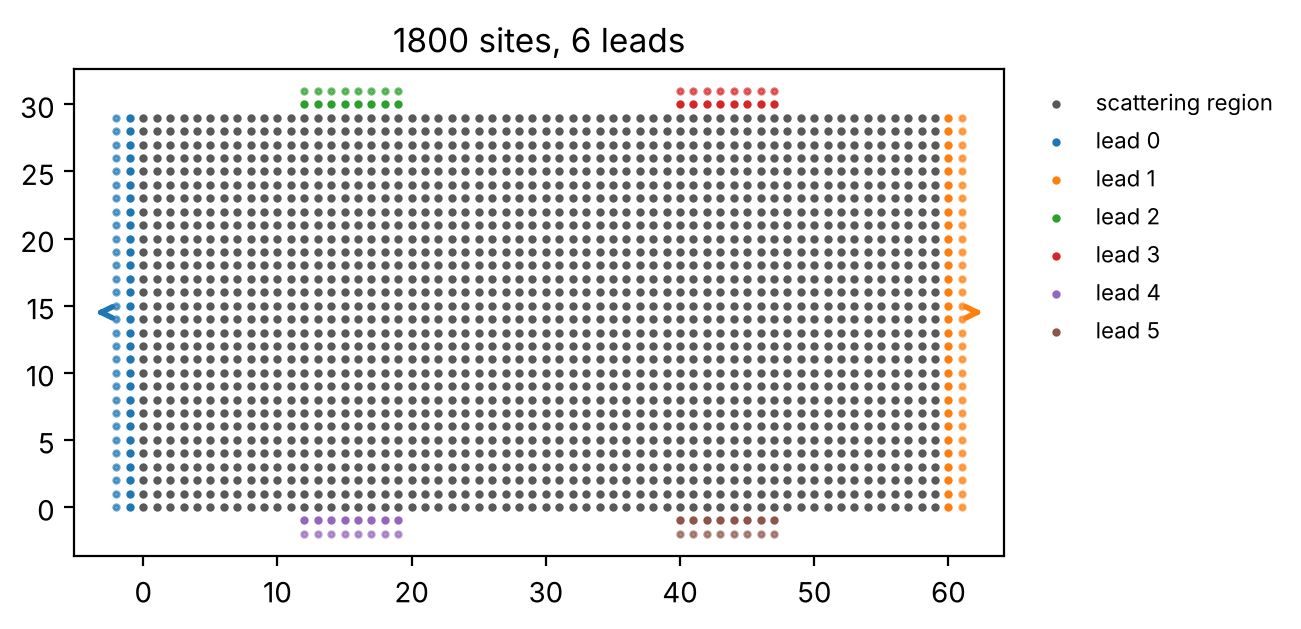

In [2]:
B = 2*np.pi*0.05          # 0.05 flux quanta per plaquette
def hallbar(B, L=60, W=30):
    s = tr.System(M.square(), lambda r: 0 <= r[0] < L and 0 <= r[1] < W, peierls=tr.landau_gauge(B, "x"))
    s.attach_lead((-1, 0)); s.attach_lead((1, 0))
    for x0 in (12, 40): s.attach_lead((0, 1),  shape=lambda r, x0=x0: x0 <= r[0] < x0 + 8, peierls=None)
    for x0 in (12, 40): s.attach_lead((0, -1), shape=lambda r, x0=x0: x0 <= r[0] < x0 + 8, peierls=None)
    return s
hb = hallbar(B)
tr.plot_system(hb, bonds=False);

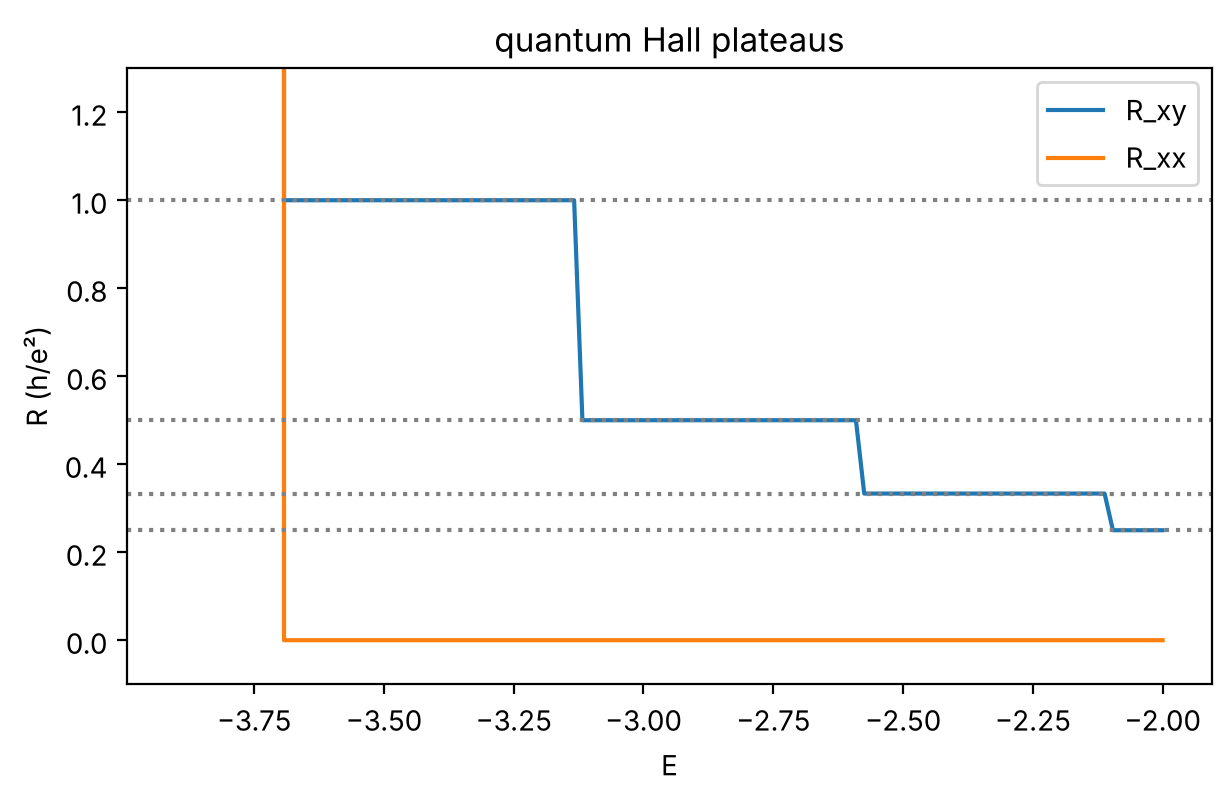

In [3]:
Es = np.linspace(-3.9, -2.0, 120)
Rxy, Rxx = [], []
for E in Es:
    S = hb.smatrix(E)
    Rxy.append(S.four_terminal_resistance(0, 1, 2, 4)); Rxx.append(S.four_terminal_resistance(0, 1, 2, 3))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Es, Rxy, label="R_xy"); ax.plot(Es, Rxx, label="R_xx")
for nu in (1, 2, 3, 4): ax.axhline(1/nu, c="gray", ls=":")
ax.set_ylim(-0.1, 1.3); ax.set_xlabel("E"); ax.set_ylabel("R (h/e²)"); ax.legend(); ax.set_title("quantum Hall plateaus");

## 2. Edge-state current flow

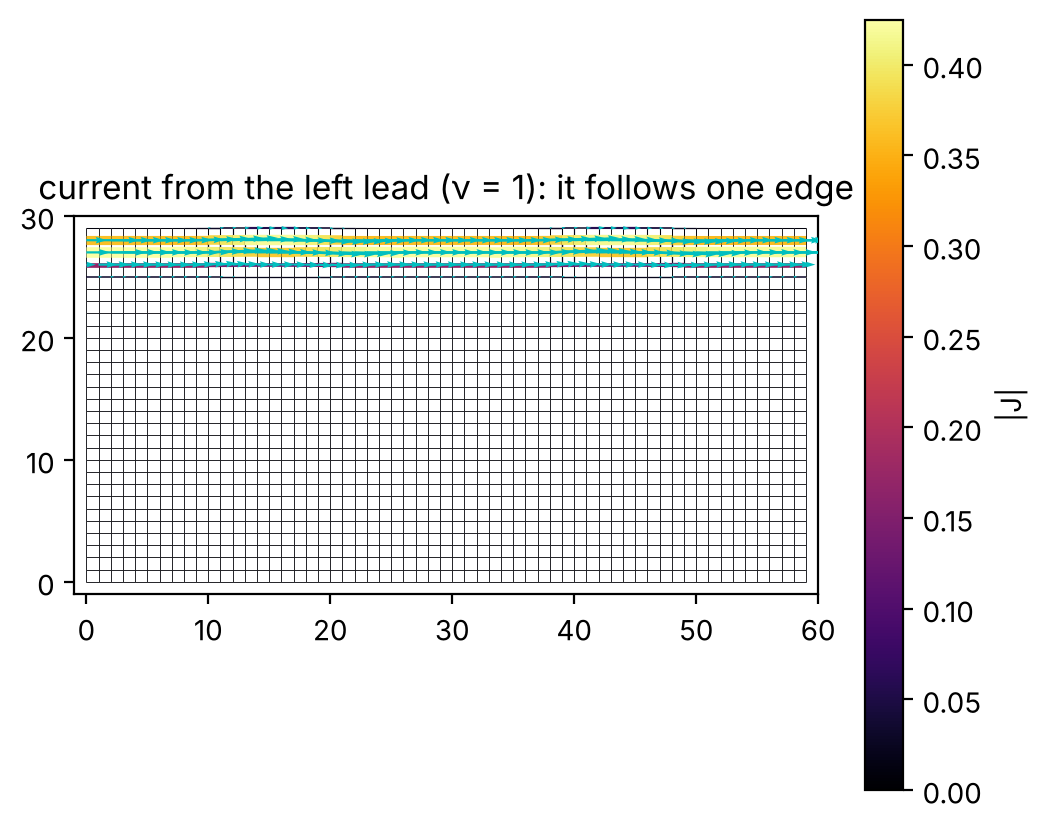

In [4]:
S = hb.smatrix(-3.4)
bonds, J = S.current(0)
tr.plot_current(hb, bonds, J, title="current from the left lead (ν = 1): it follows one edge");

## 3. Landau fan: T between the current leads versus B

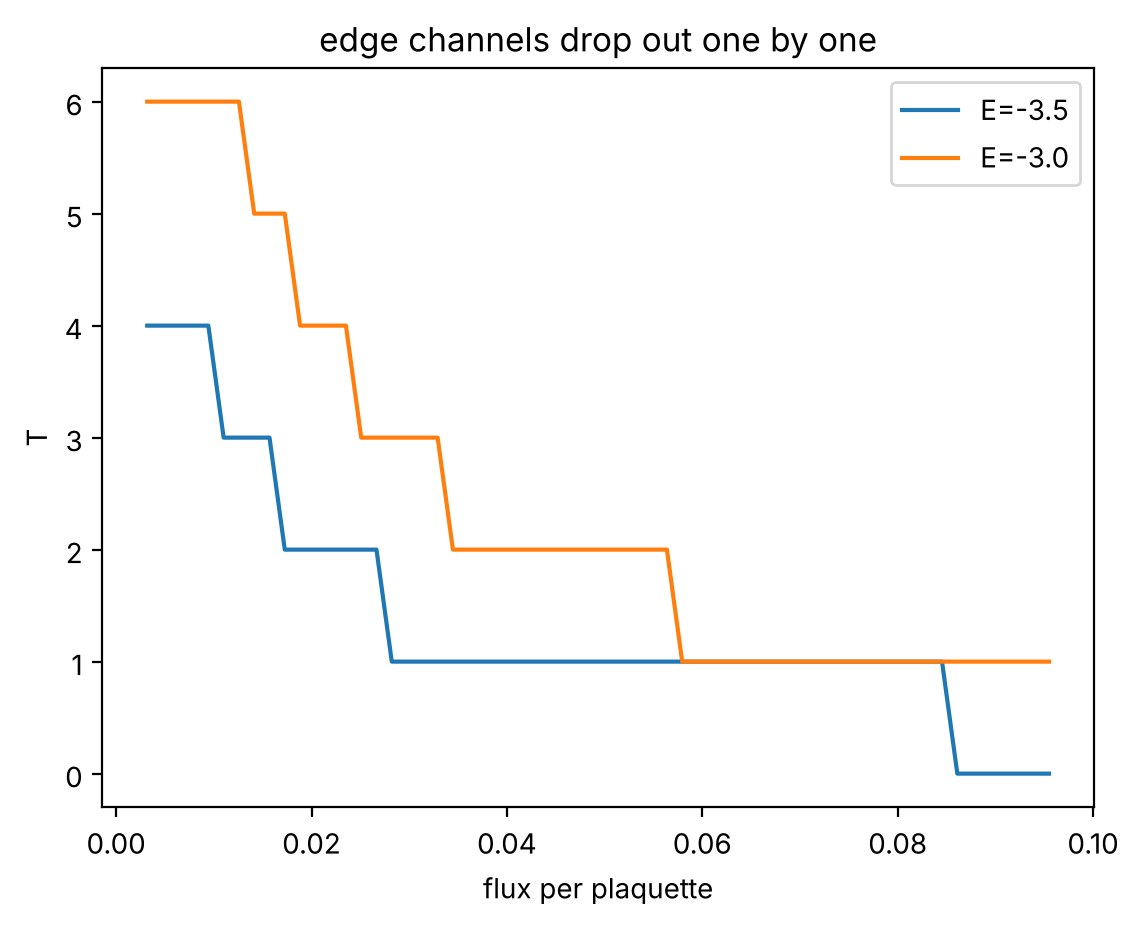

In [5]:
Bs = np.linspace(0.02, 0.6, 60)
for E in (-3.5, -3.0):
    T = []
    for b in Bs:
        s = tr.System(M.square(), lambda r: 0 <= r[0] < 30 and 0 <= r[1] < 20, peierls=tr.landau_gauge(b, "x"))
        s.attach_lead((-1, 0)); s.attach_lead((1, 0))
        T.append(s.transmission(1, 0, E))
    plt.plot(Bs/(2*np.pi), T, label=f"E={E}")
plt.xlabel("flux per plaquette"); plt.ylabel("T"); plt.legend(); plt.title("edge channels drop out one by one");

## 4. Quantum spin Hall: 2e²/h, spin-resolved, robust to disorder

In [6]:
km = M.kane_mele(lso=0.1)
for W in (0.0, 1.0, 2.0):
    s = tr.System(km, lambda r: 0 <= r[0] < 25 and 0 <= r[1] < 15, onsite=tr.anderson(W, seed=3) if W else None)
    s.attach_lead((-1, 0)); s.attach_lead((1, 0))
    S = s.smatrix(0.05)
    up = dict(spin="up"); dn = dict(spin="down")
    print(f"W={W}: T={S.transmission(1,0):.4f}   T_upup={S.transmission(1,0,up,up):.4f}   T_dndn={S.transmission(1,0,dn,dn):.4f}")

W=0.0: T=2.0000   T_upup=1.0000   T_dndn=1.0000
W=1.0: T=2.0000   T_upup=1.0000   T_dndn=1.0000


W=2.0: T=2.0000   T_upup=1.0000   T_dndn=1.0000


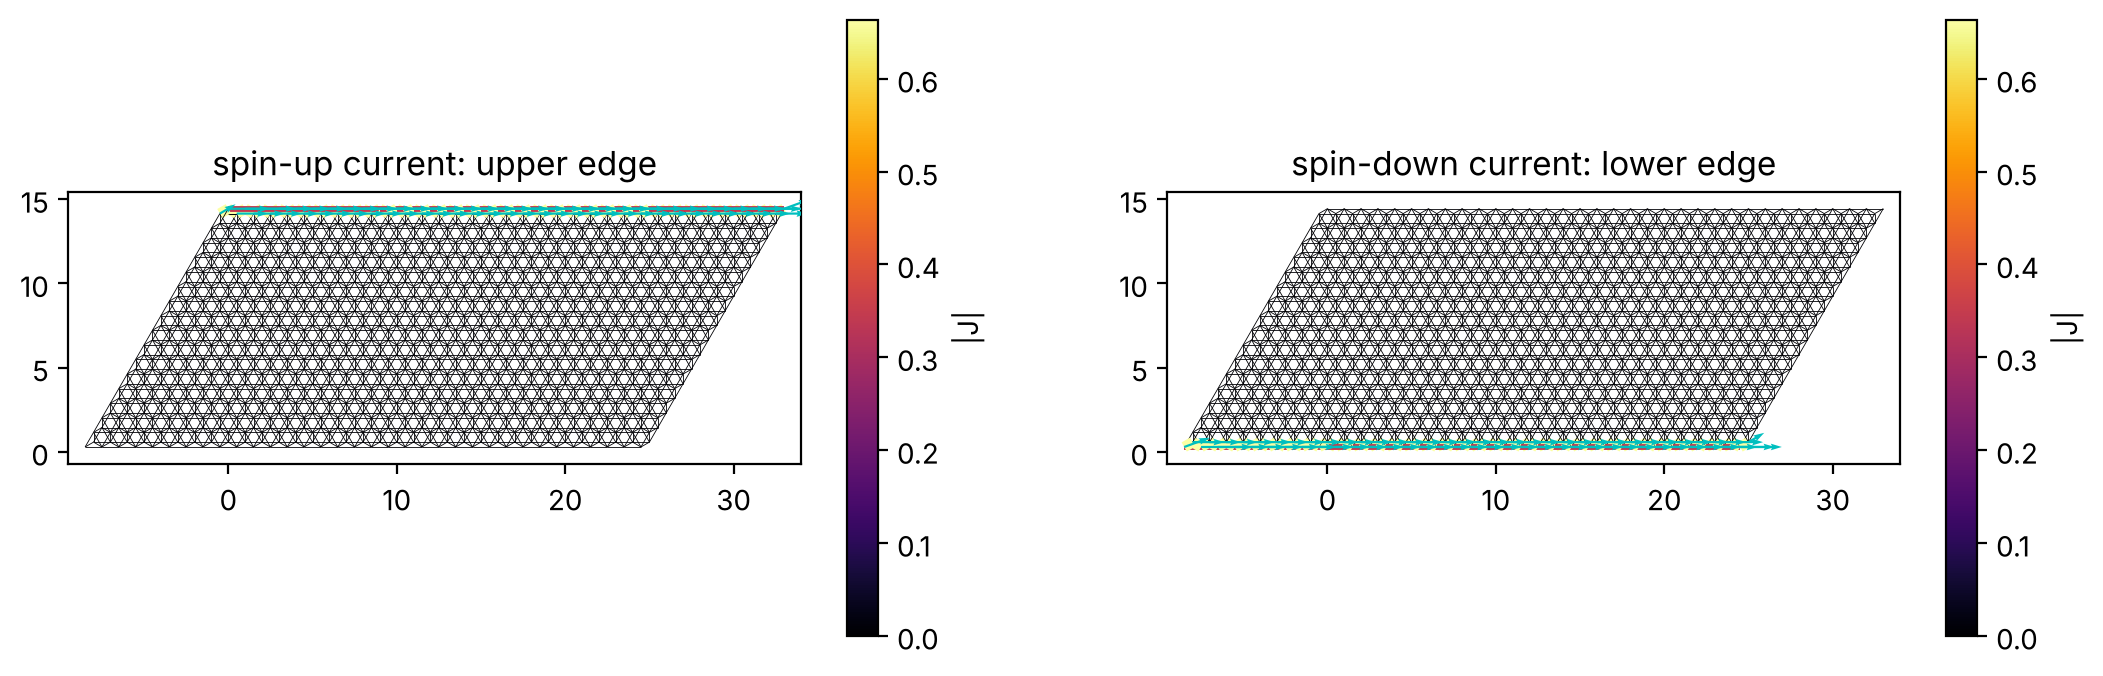

In [7]:
s = tr.System(km, lambda r: 0 <= r[0] < 25 and 0 <= r[1] < 15)
s.attach_lead((-1, 0)); s.attach_lead((1, 0))
S = s.smatrix(0.05)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
b, Jup = S.current(0, operator=np.diag([1, 0]))
tr.plot_current(s, b, Jup, ax=axes[0], title="spin-up current: upper edge")
b, Jdn = S.current(0, operator=np.diag([0, 1]))
tr.plot_current(s, b, Jdn, ax=axes[1], title="spin-down current: lower edge");

## 5. Breaking time reversal: a Zeeman field on the QSH edge

In [8]:
for J in (0.0, 0.05, 0.2):
    s = tr.System(M.kane_mele(lso=0.1), lambda r: 0 <= r[0] < 25 and 0 <= r[1] < 15,
                  onsite=lambda r, n, J=J: J * hf.pauli('x'))       # in-plane Zeeman in the region only
    s.attach_lead((-1, 0)); s.attach_lead((1, 0))
    print(f"in-plane Zeeman J={J}: T(E=0) = {s.transmission(1, 0, 0.0):.4f}")

in-plane Zeeman J=0.0: T(E=0) = 2.0000


in-plane Zeeman J=0.05: T(E=0) = 0.0276


in-plane Zeeman J=0.2: T(E=0) = 0.0000


Breaking time reversal opens a gap at the edge Dirac point, so the edge states backscatter and the conductance at E = 0 is lost.

## Exercises
1. Reverse B and verify the Onsager relation $R_{xy}(B)=-R_{xy}(-B)$.
2. Add disorder to the Hall bar: how wide do the plateaus stay?
3. Build a graphene Hall bar and find the half-integer sequence ν = ±2, ±6, …

---
## Quiz 09: Multi-terminal, QH and QSH

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [9]:
quiz = hf.Quiz(9)
quiz.interactive()

In [10]:
quiz.show()

=== Quiz 09: Multi-terminal transport, quantum Hall and quantum spin Hall ===

Q1. In the Landauer-Buettiker formalism the current in lead i is
   (a) I_i = T_ii
   (b) I_i = (e/h) sum_j G_ij V_j with G_ij = -T_ij (i != j)
   (c) I_i = V_i / R
   (d) I_i = 0

Q2. Why does one voltage have to be fixed (grounded) when solving I = G V?
   (a) for speed
   (b) to avoid magnetic fields
   (c) G is singular: only voltage differences matter
   (d) it does not

Q3. A four-terminal resistance R_ij,kl measures
   (a) the DOS
   (b) the contact resistance only
   (c) the Hall angle
   (d) V_k - V_l with current from i to j

Q4. On a quantum Hall plateau with filling nu, the Hall resistance is
   (a) h/(nu e^2)
   (b) nu h/e^2
   (c) 0
   (d) h/e^2 always

Q5. On a quantum Hall plateau, the longitudinal resistance R_xx
   (a) is maximal
   (b) diverges
   (c) is h/e^2
   (d) vanishes (no backscattering between counter-propagating edges)

Q6. The Peierls substitution for a field B in the Landau gau

In [11]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0